# 06 - Statistical inference, distribution checks, and protection-period uncertainty

This notebook adds the inferential layer required for the AAI 500 final project. It uses only training and validation outputs. Final-test sales remain unavailable.

The objectives are to:

1. examine whether common probability distributions are plausible for weekly sales;
2. use cluster bootstrap resampling to quantify uncertainty in forecast comparisons and interval coverage;
3. show how a normal approximation relates to a bootstrap sampling distribution without assuming daily observations are independent; and
4. calibrate the 14-day protection period required by a 7-day lead time plus a 7-day review interval.

The notebook does not introduce an advanced machine-learning model.

## 1. Imports, project paths, and reproducibility

The random generator uses a fixed seed. Bootstrap resampling treats a complete product-store series as a cluster, preserving the four validation weeks within that series.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "statistical_inference"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_END = 1885
VALIDATION_START = 1886
VALIDATION_END = 1913
LEAD_TIME_DAYS = 7
REVIEW_PERIOD_DAYS = 7
PROTECTION_PERIOD_DAYS = LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS
TARGET_QUANTILES = [0.80, 0.90, 0.95]
BOOTSTRAP_REPETITIONS = 5000
QUANTILE_BOOTSTRAP_REPETITIONS = 2000
RANDOM_SEED = 500

rng = np.random.default_rng(RANDOM_SEED)
print(f"Project root: {PROJECT_ROOT}")
print(f"Protection period: {PROTECTION_PERIOD_DAYS} days")

Project root: /Users/sumitchaurasia/Desktop/USD/FinalProj/module_one_project
Protection period: 14 days


## 2. Load and verify development outputs

These files were created by notebooks 02 through 05. Assertions verify that the inferential analysis still ends at `d_1913`.

In [2]:
metadata = pd.read_csv(PROCESSED_DATA_DIR / "selected_series_metadata.csv")
development = pd.read_csv(
    PROCESSED_DATA_DIR / "selected_series_development.csv",
    parse_dates=["date"],
)
validation_forecasts = pd.read_csv(PROCESSED_DATA_DIR / "validation_point_forecasts.csv")
model_selection = pd.read_csv(PROCESSED_DATA_DIR / "forecast_model_selection.csv")
calibration_errors = pd.read_csv(PROCESSED_DATA_DIR / "weekly_uncertainty_calibration.csv")
validation_uncertainty = pd.read_csv(
    PROCESSED_DATA_DIR / "validation_weekly_probabilistic_forecasts.csv"
)

assert len(metadata) == 12
assert development["day_number"].max() == VALIDATION_END
assert validation_forecasts["day_number"].max() == VALIDATION_END
assert len(validation_uncertainty) == 12 * 4
assert calibration_errors.groupby("series_key").size().eq(52).all()

print("Verified 12 selected series and development data through d_1913 only.")

Verified 12 selected series and development data through d_1913 only.


## 3. Weekly-sales distribution diagnostics

Sales are nonnegative counts, so Poisson and negative-binomial distributions are natural candidates to inspect. A Poisson model assumes that its mean and variance are equal. A variance-to-mean ratio well above 1 indicates overdispersion and weakens that assumption.

The normal approximation is also shown because it is familiar from the course, but it is not imposed automatically. Negative predictions, strong skewness, and many zero weeks would make a normal model inappropriate.

In [3]:
training = development[development["split"] == "train"].copy()
complete_training_days = (TRAIN_END // 7) * 7
weekly_training = training[training["day_number"] <= complete_training_days].copy()
weekly_training["training_week"] = (weekly_training["day_number"] - 1) // 7 + 1

weekly_sales = (
    weekly_training.groupby(["series_key", "profile", "training_week"], observed=True)["sales"]
    .sum()
    .reset_index()
)

distribution_diagnostics = (
    weekly_sales.groupby(["series_key", "profile"], observed=True)["sales"]
    .agg(
        weeks="size",
        mean="mean",
        variance="var",
        standard_deviation="std",
        median="median",
        zero_week_share=lambda values: values.eq(0).mean(),
        skewness="skew",
    )
    .reset_index()
)
distribution_diagnostics["variance_to_mean"] = (
    distribution_diagnostics["variance"] / distribution_diagnostics["mean"]
)

for target in TARGET_QUANTILES:
    suffix = int(target * 100)
    empirical = weekly_sales.groupby("series_key", observed=True)["sales"].quantile(target)
    distribution_diagnostics[f"empirical_q{suffix}"] = distribution_diagnostics["series_key"].map(empirical)
    distribution_diagnostics[f"normal_q{suffix}"] = np.maximum(
        0,
        stats.norm.ppf(
            target,
            loc=distribution_diagnostics["mean"],
            scale=distribution_diagnostics["standard_deviation"],
        ),
    )

    poisson_values = stats.poisson.ppf(target, mu=distribution_diagnostics["mean"])
    distribution_diagnostics[f"poisson_q{suffix}"] = poisson_values

    nb_size = distribution_diagnostics["mean"] ** 2 / (
        distribution_diagnostics["variance"] - distribution_diagnostics["mean"]
    )
    nb_probability = nb_size / (nb_size + distribution_diagnostics["mean"])
    distribution_diagnostics[f"negative_binomial_q{suffix}"] = stats.nbinom.ppf(
        target,
        nb_size,
        nb_probability,
    )

display(
    distribution_diagnostics[
        [
            "series_key",
            "profile",
            "mean",
            "variance",
            "variance_to_mean",
            "zero_week_share",
            "skewness",
            "empirical_q90",
            "normal_q90",
            "poisson_q90",
            "negative_binomial_q90",
        ]
    ].round(2)
)

assert distribution_diagnostics["weeks"].eq(269).all()
assert distribution_diagnostics["variance_to_mean"].gt(1).all()

,series_key,profile,mean,variance,variance_to_mean,zero_week_share,skewness,empirical_q90,normal_q90,poisson_q90,negative_binomial_q90
0,FOODS_1_096_WI_2,weekly_pattern,104.35,11472.03,109.94,0.08,1.39,288.0,241.61,118.0,243.0
1,FOODS_2_254_TX_3,intermittent,0.93,3.20,3.43,0.70,2.20,4.0,3.22,2.0,3.0
2,FOODS_2_255_CA_4,variable,6.41,91.54,14.28,0.17,4.95,13.0,18.67,10.0,18.0
3,FOODS_3_586_CA_1,stable,321.52,3673.12,11.42,0.00,0.49,401.0,399.19,345.0,401.0
4,HOBBIES_1_209_TX_1,variable,15.19,266.10,17.51,0.01,6.93,27.2,36.10,20.0,36.0
5,HOBBIES_1_323_TX_2,weekly_pattern,30.33,158.26,5.22,0.01,0.03,48.0,46.46,37.0,47.0
6,HOBBIES_1_345_WI_1,stable,25.25,79.03,3.13,0.03,-0.43,35.0,36.64,32.0,37.0
7,HOBBIES_2_110_CA_3,intermittent,1.05,2.40,2.28,0.58,1.57,3.0,3.04,2.0,3.0
8,HOUSEHOLD_1_161_WI_3,intermittent,0.83,1.77,2.15,0.60,2.02,3.0,2.53,2.0,2.0
9,HOUSEHOLD_1_191_CA_2,weekly_pattern,49.07,1555.69,31.71,0.25,0.65,93.0,99.61,58.0,102.0


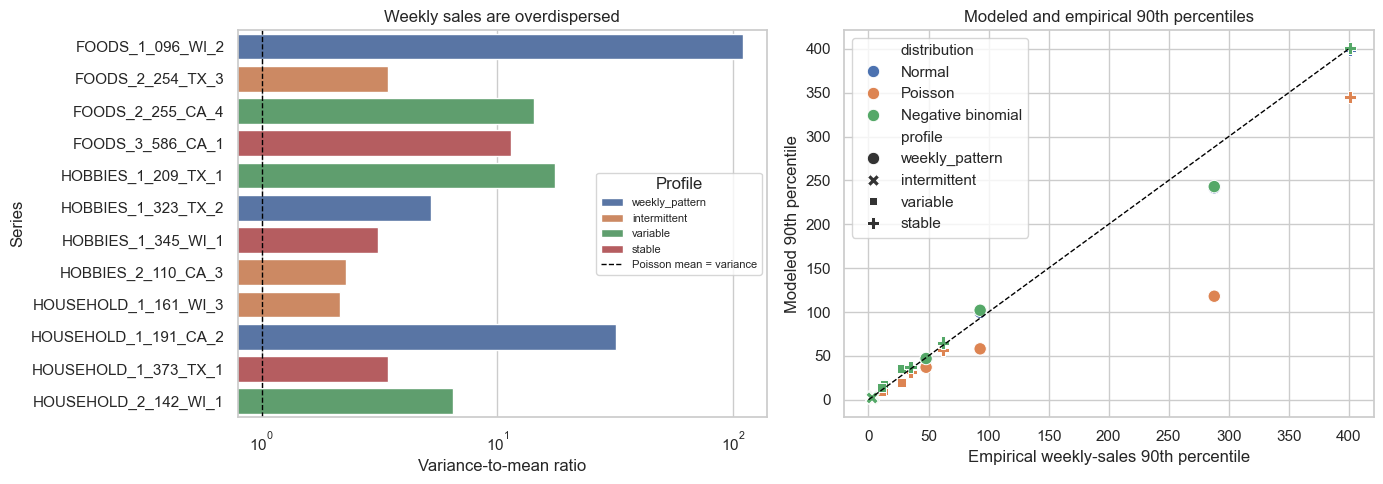

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=distribution_diagnostics,
    y="series_key",
    x="variance_to_mean",
    hue="profile",
    dodge=False,
    ax=axes[0],
)
axes[0].axvline(1, color="black", linestyle="--", linewidth=1, label="Poisson mean = variance")
axes[0].set_xscale("log")
axes[0].set(title="Weekly sales are overdispersed", xlabel="Variance-to-mean ratio", ylabel="Series")
axes[0].legend(title="Profile", fontsize=8)

quantile_plot = distribution_diagnostics.melt(
    id_vars=["series_key", "profile", "empirical_q90"],
    value_vars=["normal_q90", "poisson_q90", "negative_binomial_q90"],
    var_name="distribution",
    value_name="modeled_q90",
)
quantile_plot["distribution"] = quantile_plot["distribution"].map(
    {
        "normal_q90": "Normal",
        "poisson_q90": "Poisson",
        "negative_binomial_q90": "Negative binomial",
    }
)
sns.scatterplot(
    data=quantile_plot,
    x="empirical_q90",
    y="modeled_q90",
    hue="distribution",
    style="profile",
    s=80,
    ax=axes[1],
)
quantile_limit = max(quantile_plot["empirical_q90"].max(), quantile_plot["modeled_q90"].max())
axes[1].plot([0, quantile_limit], [0, quantile_limit], color="black", linestyle="--", linewidth=1)
axes[1].set(
    title="Modeled and empirical 90th percentiles",
    xlabel="Empirical weekly-sales 90th percentile",
    ylabel="Modeled 90th percentile",
)

plt.tight_layout()
fig.savefig(FIGURE_DIR / "weekly_distribution_diagnostics.png", dpi=300, bbox_inches="tight")
plt.show()

### Distribution inference

Every selected series has weekly variance greater than its weekly mean, so the basic Poisson equal-mean-and-variance assumption is not supported. Normal and negative-binomial quantiles can be useful comparisons, but neither is automatically accepted. The main safety-stock method continues to use empirical forecast errors because it preserves observed skewness and does not require one distribution to fit all four demand profiles.

## 4. Cluster bootstrap for forecast-model comparison

Daily errors within the same series are related over time. Resampling individual days would treat them as independent and understate uncertainty. The bootstrap therefore samples the 12 complete series with replacement and retains all four validation weeks for every sampled series.

The intervals describe stability across the selected series. Because the 12 series form a purposive sample, they are not population confidence intervals for all M5 products.

In [5]:
validation_forecasts["validation_week"] = (validation_forecasts["horizon"] - 1) // 7 + 1
weekly_model_error = (
    validation_forecasts.groupby(
        ["series_key", "profile", "model", "validation_week"],
        observed=True,
    )["absolute_error"]
    .mean()
    .reset_index(name="weekly_mae")
)

series_model_mae = (
    weekly_model_error.groupby(["series_key", "model"], observed=True)["weekly_mae"]
    .mean()
    .unstack("model")
    .reindex(metadata["series_key"])
)

model_names = ["last_value", "seasonal_naive_7", "mean_28"]
bootstrap_model_means = {model: [] for model in model_names}

for _ in range(BOOTSTRAP_REPETITIONS):
    sampled_positions = rng.integers(0, len(series_model_mae), len(series_model_mae))
    sample = series_model_mae.iloc[sampled_positions]
    for model in model_names:
        bootstrap_model_means[model].append(sample[model].mean())

bootstrap_model_means = {
    model: np.asarray(values) for model, values in bootstrap_model_means.items()
}

forecast_inference_rows = []
for model in model_names:
    values = bootstrap_model_means[model]
    forecast_inference_rows.append(
        {
            "comparison": "model_mae",
            "label": model,
            "estimate": series_model_mae[model].mean(),
            "ci_lower": np.quantile(values, 0.025),
            "ci_upper": np.quantile(values, 0.975),
        }
    )

for competitor in ["seasonal_naive_7", "last_value"]:
    difference = bootstrap_model_means[competitor] - bootstrap_model_means["mean_28"]
    forecast_inference_rows.append(
        {
            "comparison": "mae_difference_vs_mean_28",
            "label": competitor,
            "estimate": series_model_mae[competitor].mean() - series_model_mae["mean_28"].mean(),
            "ci_lower": np.quantile(difference, 0.025),
            "ci_upper": np.quantile(difference, 0.975),
        }
    )

forecast_inference = pd.DataFrame(forecast_inference_rows)
display(forecast_inference.round(3))

,comparison,label,estimate,ci_lower,ci_upper
0,model_mae,last_value,4.905,1.768,9.289
1,model_mae,seasonal_naive_7,3.250,1.717,5.081
2,model_mae,mean_28,3.121,1.500,5.021
3,mae_difference_vs_mean_28,seasonal_naive_7,0.129,-0.357,0.587
4,mae_difference_vs_mean_28,last_value,1.784,-0.121,4.682


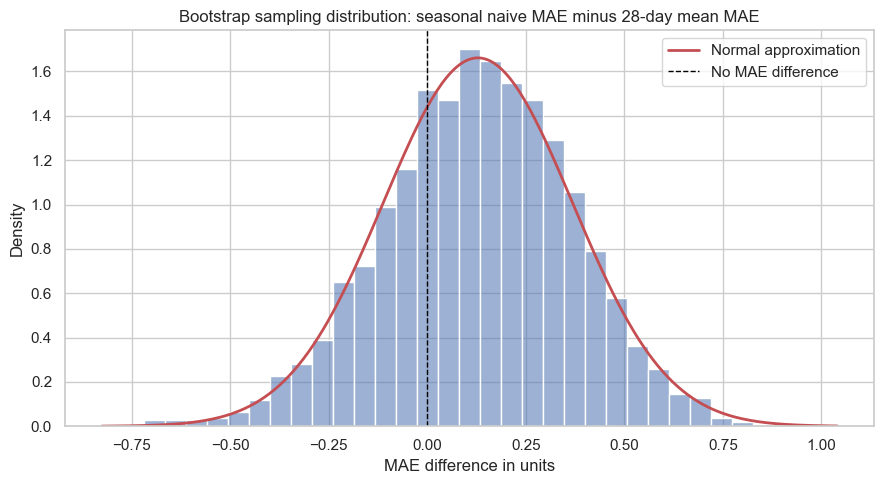

In [6]:
difference = bootstrap_model_means["seasonal_naive_7"] - bootstrap_model_means["mean_28"]
difference_mean = difference.mean()
difference_std = difference.std(ddof=1)
x_values = np.linspace(difference.min(), difference.max(), 300)

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(difference, bins=35, stat="density", color="#4C72B0", alpha=0.55, ax=ax)
ax.plot(
    x_values,
    stats.norm.pdf(x_values, loc=difference_mean, scale=difference_std),
    color="#C44E52",
    linewidth=2,
    label="Normal approximation",
)
ax.axvline(0, color="black", linestyle="--", linewidth=1, label="No MAE difference")
ax.set(
    title="Bootstrap sampling distribution: seasonal naive MAE minus 28-day mean MAE",
    xlabel="MAE difference in units",
    ylabel="Density",
)
ax.legend()
plt.tight_layout()
fig.savefig(FIGURE_DIR / "bootstrap_mae_difference.png", dpi=300, bbox_inches="tight")
plt.show()

### Bootstrap and Central Limit Theorem interpretation

The histogram is an empirical sampling distribution of an average error difference. The overlaid normal curve illustrates the normal approximation motivated by the Central Limit Theorem. The percentile bootstrap interval is used for the reported inference because there are only 12 series and the sample was intentionally selected. An interval containing zero means that the observed ranking is not stable enough to claim a clear average difference across these selected series.

## 5. Cluster bootstrap for interval coverage

Coverage is a sample proportion. Its observed value can change noticeably with only 48 weekly outcomes. Resampling at the series level retains the four outcomes belonging to the same series.

,interval,target_coverage_pct,observed_coverage_pct,ci_lower_pct,ci_upper_pct
0,Central 80%,80.0,79.17,68.75,89.58
1,Central 90%,90.0,85.42,72.92,95.83


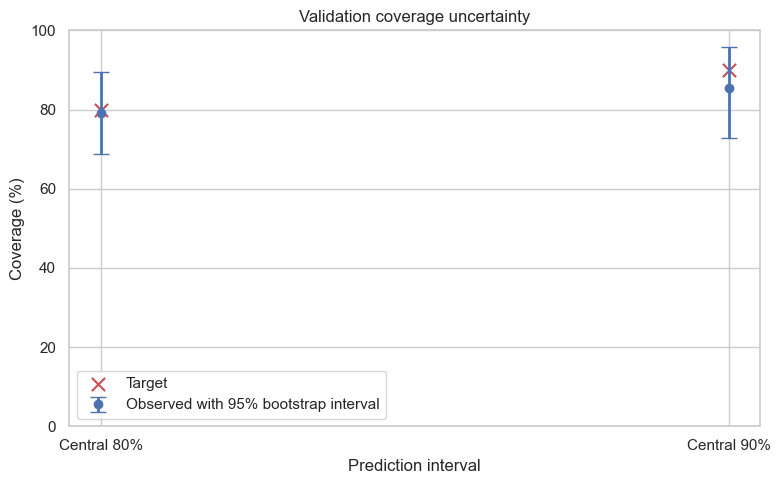

In [7]:
coverage_by_series = (
    validation_uncertainty.set_index(["series_key", "validation_week"])
    .reindex(
        pd.MultiIndex.from_product(
            [metadata["series_key"], range(1, 5)],
            names=["series_key", "validation_week"],
        )
    )[["covered_80", "covered_90"]]
)

coverage_arrays = {
    80: coverage_by_series["covered_80"].to_numpy().reshape(12, 4),
    90: coverage_by_series["covered_90"].to_numpy().reshape(12, 4),
}

coverage_inference_rows = []
coverage_bootstrap_values = {}
for level, values in coverage_arrays.items():
    bootstrap_values = []
    for _ in range(BOOTSTRAP_REPETITIONS):
        sampled_positions = rng.integers(0, values.shape[0], values.shape[0])
        bootstrap_values.append(100 * values[sampled_positions].mean())
    bootstrap_values = np.asarray(bootstrap_values)
    coverage_bootstrap_values[level] = bootstrap_values
    coverage_inference_rows.append(
        {
            "interval": f"Central {level}%",
            "target_coverage_pct": float(level),
            "observed_coverage_pct": 100 * values.mean(),
            "ci_lower_pct": np.quantile(bootstrap_values, 0.025),
            "ci_upper_pct": np.quantile(bootstrap_values, 0.975),
        }
    )

coverage_inference = pd.DataFrame(coverage_inference_rows)
display(coverage_inference.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
positions = np.arange(len(coverage_inference))
estimates = coverage_inference["observed_coverage_pct"].to_numpy()
errors = np.vstack(
    [
        estimates - coverage_inference["ci_lower_pct"].to_numpy(),
        coverage_inference["ci_upper_pct"].to_numpy() - estimates,
    ]
)
ax.errorbar(positions, estimates, yerr=errors, fmt="o", capsize=6, linewidth=2, label="Observed with 95% bootstrap interval")
ax.scatter(positions, coverage_inference["target_coverage_pct"], marker="x", s=90, color="#C44E52", label="Target")
ax.set(
    xticks=positions,
    xticklabels=coverage_inference["interval"],
    ylim=(0, 100),
    title="Validation coverage uncertainty",
    xlabel="Prediction interval",
    ylabel="Coverage (%)",
)
ax.legend()
plt.tight_layout()
fig.savefig(FIGURE_DIR / "bootstrap_coverage_intervals.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Bootstrap uncertainty in seven-day safety stock

The empirical 80th, 90th, and 95th error quantiles were estimated from 52 weekly errors per series. Resampling those 52 errors shows how much the estimated buffer can change with the available calibration sample.

In [8]:
safety_stock_uncertainty_rows = []

for series_key, series_errors in calibration_errors.groupby("series_key", observed=True):
    errors = series_errors["forecast_error"].to_numpy(dtype="float64")
    profile = series_errors["profile"].iat[0]

    for target in TARGET_QUANTILES:
        bootstrap_buffers = []
        for _ in range(QUANTILE_BOOTSTRAP_REPETITIONS):
            sample = rng.choice(errors, size=len(errors), replace=True)
            bootstrap_buffers.append(max(0.0, np.quantile(sample, target)))
        bootstrap_buffers = np.asarray(bootstrap_buffers)
        estimate = max(0.0, np.quantile(errors, target))
        safety_stock_uncertainty_rows.append(
            {
                "series_key": series_key,
                "profile": profile,
                "target_quantile": target,
                "safety_stock_estimate": estimate,
                "bootstrap_median": np.median(bootstrap_buffers),
                "ci_lower": np.quantile(bootstrap_buffers, 0.025),
                "ci_upper": np.quantile(bootstrap_buffers, 0.975),
            }
        )

safety_stock_uncertainty = pd.DataFrame(safety_stock_uncertainty_rows)
display(safety_stock_uncertainty.head(12).round(2))

,series_key,profile,target_quantile,safety_stock_estimate,bootstrap_median,ci_lower,ci_upper
0,FOODS_1_096_WI_2,weekly_pattern,0.80,53.40,53.40,28.85,69.10
1,FOODS_1_096_WI_2,weekly_pattern,0.90,69.30,69.30,53.17,95.50
2,FOODS_1_096_WI_2,weekly_pattern,0.95,88.21,88.21,64.06,109.47
3,FOODS_2_254_TX_3,intermittent,0.80,1.15,1.15,0.00,2.45
4,FOODS_2_254_TX_3,intermittent,0.90,2.47,2.47,0.75,4.00
5,FOODS_2_254_TX_3,intermittent,0.95,3.86,3.86,1.97,5.24
6,FOODS_2_255_CA_4,variable,0.80,2.95,2.95,1.65,7.00
7,FOODS_2_255_CA_4,variable,0.90,7.12,7.12,2.75,14.25
8,FOODS_2_255_CA_4,variable,0.95,11.91,11.91,4.35,26.17
9,FOODS_3_586_CA_1,stable,0.80,37.80,37.80,15.00,57.60


## 7. Calibrate the 14-day periodic-review protection period

Notebook 05 calculated uncertainty for seven-day lead-time demand. A periodic-review policy with a 7-day review interval and a 7-day replenishment lead time must protect against demand over both periods:

```text
protection period = review interval + lead time = 14 days
```

The same selected statistical baseline is therefore recalibrated on 14-day totals before the inventory simulation. This correction is made using training data only.

In [9]:
def baseline_forecast(history, model, horizon):
    if model == "last_value":
        forecast = np.repeat(history[-1], horizon)
    elif model == "seasonal_naive_7":
        forecast = np.resize(history[-7:], horizon)
    elif model == "mean_28":
        forecast = np.repeat(history[-28:].mean(), horizon)
    else:
        raise ValueError(f"Unknown model: {model}")
    return np.maximum(forecast.astype("float64"), 0.0)


series_order = metadata["series_key"].tolist()
training_wide = (
    development[development["split"] == "train"]
    .pivot(index="series_key", columns="day_number", values="sales")
    .reindex(index=series_order, columns=range(1, TRAIN_END + 1))
)

protection_calibration_rows = []
for series_key in series_order:
    history = training_wide.loc[series_key].to_numpy(dtype="float64")
    selected_model = model_selection.loc[
        model_selection["series_key"] == series_key, "selected_model"
    ].iat[0]
    profile = metadata.loc[metadata["series_key"] == series_key, "profile"].iat[0]
    first_origin = len(history) - 364
    origins = range(first_origin, len(history) - PROTECTION_PERIOD_DAYS + 1, REVIEW_PERIOD_DAYS)

    for origin in origins:
        point_forecast = baseline_forecast(history[:origin], selected_model, PROTECTION_PERIOD_DAYS).sum()
        actual = history[origin : origin + PROTECTION_PERIOD_DAYS].sum()
        protection_calibration_rows.append(
            {
                "series_key": series_key,
                "profile": profile,
                "selected_model": selected_model,
                "origin_day": origin,
                "actual_protection_period_sales": actual,
                "forecast_protection_period_sales": point_forecast,
                "forecast_error": actual - point_forecast,
            }
        )

protection_calibration = pd.DataFrame(protection_calibration_rows)
protection_error_quantiles = (
    protection_calibration.groupby(["series_key", "profile", "selected_model"])["forecast_error"]
    .quantile(TARGET_QUANTILES)
    .unstack()
    .reset_index()
    .rename(columns={0.80: "error_q80", 0.90: "error_q90", 0.95: "error_q95"})
)

for target in TARGET_QUANTILES:
    suffix = int(target * 100)
    protection_error_quantiles[f"buffer_q{suffix}"] = protection_error_quantiles[f"error_q{suffix}"].clip(lower=0)

display(protection_error_quantiles.round(2))
assert protection_calibration.groupby("series_key").size().nunique() == 1
assert protection_error_quantiles[["buffer_q80", "buffer_q90", "buffer_q95"]].ge(0).all().all()

,series_key,profile,selected_model,error_q80,error_q90,error_q95,buffer_q80,buffer_q90,buffer_q95
0,FOODS_1_096_WI_2,weekly_pattern,mean_28,105.5,138.0,166.00,105.5,138.0,166.00
1,FOODS_2_254_TX_3,intermittent,mean_28,2.0,6.0,7.75,2.0,6.0,7.75
2,FOODS_2_255_CA_4,variable,mean_28,6.0,9.0,19.50,6.0,9.0,19.50
3,FOODS_3_586_CA_1,stable,seasonal_naive_7,60.0,96.0,114.00,60.0,96.0,114.00
4,HOBBIES_1_209_TX_1,variable,mean_28,9.0,12.0,12.75,9.0,12.0,12.75
5,HOBBIES_1_323_TX_2,weekly_pattern,mean_28,6.5,11.0,12.50,6.5,11.0,12.50
6,HOBBIES_1_345_WI_1,stable,mean_28,7.5,9.0,10.75,7.5,9.0,10.75
7,HOBBIES_2_110_CA_3,intermittent,seasonal_naive_7,2.0,5.0,6.00,2.0,5.0,6.00
8,HOUSEHOLD_1_161_WI_3,intermittent,seasonal_naive_7,3.0,4.0,5.00,3.0,4.0,5.00
9,HOUSEHOLD_1_191_CA_2,weekly_pattern,last_value,0.0,68.0,82.00,0.0,68.0,82.00


## 8. Save inferential outputs

The final simulation will use the training-only 14-day protection-period quantiles. Bootstrap tables remain separate so estimates and their uncertainty are not confused.

In [10]:
distribution_output = PROCESSED_DATA_DIR / "weekly_distribution_diagnostics.csv"
forecast_output = PROCESSED_DATA_DIR / "bootstrap_forecast_inference.csv"
coverage_output = PROCESSED_DATA_DIR / "bootstrap_coverage_inference.csv"
safety_output = PROCESSED_DATA_DIR / "bootstrap_safety_stock_uncertainty.csv"
protection_calibration_output = PROCESSED_DATA_DIR / "protection_period_calibration.csv"
protection_quantiles_output = PROCESSED_DATA_DIR / "protection_period_error_quantiles.csv"

distribution_diagnostics.to_csv(distribution_output, index=False)
forecast_inference.to_csv(forecast_output, index=False)
coverage_inference.to_csv(coverage_output, index=False)
safety_stock_uncertainty.to_csv(safety_output, index=False)
protection_calibration.to_csv(protection_calibration_output, index=False)
protection_error_quantiles.to_csv(protection_quantiles_output, index=False)

saved_outputs = pd.DataFrame(
    {
        "file": [
            distribution_output.name,
            forecast_output.name,
            coverage_output.name,
            safety_output.name,
            protection_calibration_output.name,
            protection_quantiles_output.name,
        ],
        "rows": [
            len(distribution_diagnostics),
            len(forecast_inference),
            len(coverage_inference),
            len(safety_stock_uncertainty),
            len(protection_calibration),
            len(protection_error_quantiles),
        ],
    }
)
display(saved_outputs)
print("Inferential outputs saved without loading final-test sales.")

,file,rows
0,weekly_distribution_diagnostics.csv,12
1,bootstrap_forecast_inference.csv,5
2,bootstrap_coverage_inference.csv,2
3,bootstrap_safety_stock_uncertainty.csv,36
4,protection_period_calibration.csv,612
5,protection_period_error_quantiles.csv,12


Inferential outputs saved without loading final-test sales.


## 9. Conclusion

The formal inference changes how the earlier point estimates should be described:

- The 28-day mean has the lowest observed validation MAE, but its advantage over seasonal naive is only 0.129 units. The 95% cluster-bootstrap interval for `seasonal naive - mean 28` is -0.357 to 0.587, which includes zero. The observed ranking is therefore not a clear average difference across the 12 selected series.
- Last value is 1.784 MAE units worse than the 28-day mean, but its interval of -0.121 to 4.682 also includes zero because performance varies sharply by series.
- Central 80% coverage is 79.17%, with a cluster-bootstrap interval of 68.75% to 89.58%.
- Central 90% coverage is 85.42%, with an interval of 72.92% to 95.83%. The point estimate undercovers, but the available 48 weekly outcomes are not precise enough to establish the true selected-series coverage narrowly.
- Safety-stock quantiles have substantial uncertainty for several series. For example, the 90th-percentile buffer for `FOODS_1_096_WI_2` is 69.30 units with a bootstrap interval from 53.18 to 95.50 units.

Weekly variance exceeds weekly mean for every selected series, so a common Poisson model is too restrictive. Empirical forecast errors remain the main probability model. Normal and negative-binomial results are diagnostic comparisons rather than replacements chosen after seeing favorable results.

The training-only 14-day protection-period calibration is now ready for the final inventory simulation.